In [1]:
# import needed modules/libraries
import os, pysam
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sn
from tqdm import tqdm

In [2]:
anno = pd.read_table("/lustre/bio_running/GTEx_Long_Project/gencode.v49.basic.annotation.gtf.chrM.gtf.lengths_info.tsv")
anno["len"] = (anno["stop"] - anno["start"]) + 1
anno["gene_type"] = anno["gene_type"].apply(lambda x: x[1:-1])
anno["gene_name"] = anno["gene_name"].apply(lambda x: x[1:-1])
anno

,Region,track,start,stop,strand,attributes,gene_ids,gene_type,gene_name,len
0,chrM,gene,577,647,+,"gene_id ""ENSG00000210049.1""; gene_type ""Mt_tRN...","""ENSG00000210049.1""",Mt_tRNA,MT-TF,71
1,chrM,gene,648,1601,+,"gene_id ""ENSG00000211459.2""; gene_type ""Mt_rRN...","""ENSG00000211459.2""",Mt_rRNA,MT-RNR1,954
2,chrM,gene,1602,1670,+,"gene_id ""ENSG00000210077.1""; gene_type ""Mt_tRN...","""ENSG00000210077.1""",Mt_tRNA,MT-TV,69
3,chrM,gene,1671,3229,+,"gene_id ""ENSG00000210082.2""; gene_type ""Mt_rRN...","""ENSG00000210082.2""",Mt_rRNA,MT-RNR2,1559
4,chrM,gene,3230,3304,+,"gene_id ""ENSG00000209082.1""; gene_type ""Mt_tRN...","""ENSG00000209082.1""",Mt_tRNA,MT-TL1,75
5,chrM,gene,3307,4262,+,"gene_id ""ENSG00000198888.2""; gene_type ""protei...","""ENSG00000198888.2""",protein_coding,MT-ND1,956
6,chrM,gene,4263,4331,+,"gene_id ""ENSG00000210100.1""; gene_type ""Mt_tRN...","""ENSG00000210100.1""",Mt_tRNA,MT-TI,69
7,chrM,gene,4329,4400,-,"gene_id ""ENSG00000210107.1""; gene_type ""Mt_tRN...","""ENSG00000210107.1""",Mt_tRNA,MT-TQ,72
8,chrM,gene,4402,4469,+,"gene_id ""ENSG00000210112.1""; gene_type ""Mt_tRN...","""ENSG00000210112.1""",Mt_tRNA,MT-TM,68
9,chrM,gene,4470,5511,+,"gene_id ""ENSG00000198763.3""; gene_type ""protei...","""ENSG00000198763.3""",protein_coding,MT-ND2,1042


In [3]:
anno.groupby(["gene_type"]).describe()["len"]

,count,mean,std,min,25%,50%,75%,max
gene_type,,,,,,,,
7S,1.0,218.000000,NaN,218.0,218.00,218.0,218.00,218.0
Mt_rRNA,2.0,1256.500000,427.799603,954.0,1105.25,1256.5,1407.75,1559.0
Mt_tRNA,22.0,68.545455,3.188182,59.0,68.00,69.0,69.75,75.0
protein_coding,13.0,876.538462,495.487069,207.0,525.00,784.0,1141.00,1812.0


In [4]:
anno.groupby(["gene_type", "strand"]).describe()["len"]

count         mean         std    min      25%     50%  \
gene_type      strand                                                           
7S             -         1.0   218.000000         NaN  218.0   218.00   218.0   
Mt_rRNA        +         2.0  1256.500000  427.799603  954.0  1105.25  1256.5   
Mt_tRNA        +        14.0    68.285714    3.582620   59.0    68.00    68.5   
               -         8.0    69.000000    2.507133   66.0    67.50    69.0   
protein_coding +        12.0   905.833333  505.623977  207.0   597.25   870.0   
               -         1.0   525.000000         NaN  525.0   525.00   525.0   

                           75%     max  
gene_type      strand                   
7S             -        218.00   218.0  
Mt_rRNA        +       1407.75  1559.0  
Mt_tRNA        +         69.75    75.0  
               -         69.75    73.0  
protein_coding +       1200.25  1812.0  
               -        525.00   525.0

In [5]:
# load reverse strand reads classification
df_rev = pd.read_table("/lustre/bio_running/GTEx_Long_Project/metadata/GTEx.chrM_info_extended.7S.reverse.reads.classified.v2.tsv")
df_rev

,Chr,ChrStart,ChrEnd,read_id,MAPQ,strand,read_length,alignment_length,reference_length,polyA_length,...,ENSG00000198695.2,ENSG00000198695.2 (%),ENSG00000210194.1,ENSG00000210194.1 (%),ENSG00000210196.2,ENSG00000210196.2 (%),overlapping_gene_ids,overlapping_gene_names,n_overlapping_gene_ids,chrM_primary_class
0,chrM,0,392,38a95c78-fac6-402a-bd63-93f4afd8507d,60,-,496.0,389,392,0,...,0,0.0,0,0.0,0,0.0,7S,7S,1,complete_gene
1,chrM,0,397,53c85697-26d2-491a-9786-f0a47ac51c74,60,-,503.0,395,397,8,...,0,0.0,0,0.0,0,0.0,7S,7S,1,complete_gene
2,chrM,0,397,c9885867-d20f-4c43-8c4f-8ef3f488987b,60,-,910.0,399,397,6,...,0,0.0,0,0.0,0,0.0,7S,7S,1,complete_gene
3,chrM,0,397,1f36c8de-b8e8-49d5-b59a-6de16e1a7686,60,-,605.0,399,397,4,...,0,0.0,0,0.0,0,0.0,7S,7S,1,complete_gene
4,chrM,0,397,6629b3be-1910-45d4-a1b6-d9de23087366,60,-,727.0,398,397,0,...,0,0.0,0,0.0,0,0.0,7S,7S,1,complete_gene
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3728195,chrM,16405,16569,f166ea81-0dec-4d42-b67d-81007c196b80,60,-,320.0,165,164,10,...,0,0.0,0,0.0,0,0.0,NaN,NaN,0,non_coding_region
3728196,chrM,16420,16552,7082d62c-0c11-4a40-ae97-61045c8fe402,60,-,144.0,132,132,15,...,0,0.0,0,0.0,0,0.0,NaN,NaN,0,non_coding_region
3728197,chrM,16425,16569,faa80368-2738-48d2-83c3-1cceac2f07c7,15,-,235.0,144,144,0,...,0,0.0,0,0.0,0,0.0,NaN,NaN,0,non_coding_region
3728198,chrM,16471,16569,0c55f0ba-32a6-40ce-be98-4510afb52498,59,-,166.0,98,98,27,...,0,0.0,0,0.0,0,0.0,NaN,NaN,0,non_coding_region


In [6]:
# focus on columns of intereset
coi = ['Chr', 'ChrStart', 'ChrEnd', 'read_id', 'MAPQ', 'strand', 'read_length',
       'alignment_length', 'reference_length', 'polyA_length', 'sample', 'overlapping_gene_ids', 
       'overlapping_gene_names', 'n_overlapping_gene_ids', 'chrM_primary_class']
df_rev = df_rev[coi].copy()

In [7]:
df_rev.chrM_primary_class.value_counts()

partial_gene         2856384
complete_gene         421549
non_coding_region     411906
precursor_gene         38361
Name: chrM_primary_class, dtype: int64

In [8]:
df_rev.iloc[0,4:]

MAPQ                                 60
strand                                -
read_length                       496.0
alignment_length                    389
reference_length                    392
polyA_length                          0
sample                             GTA1
overlapping_gene_ids                 7S
overlapping_gene_names               7S
n_overlapping_gene_ids                1
chrM_primary_class        complete_gene
Name: 0, dtype: object

In [9]:
print(round(100 - ((df_rev.query("MAPQ >= 20").shape[0] / df_rev.shape[0]) * 100), 2), "%")

0.84 %


### L-strand

In [10]:
### 1) fully_cleaved: 
# MAPQ >= 20
# chrM_primary_class == complete_gene
# n_overlapping_gene_ids == 1 
# reference_length <= the expected track from gtf track
# start and stop within the target anno-track

indexes_to_mantain = []
with tqdm(total=df_rev.shape[0]) as pbar:
    pbar_update = int(df_rev.shape[0] / 100)
    for _,r in enumerate(df_rev.itertuples()):
        if r.MAPQ >= 20 and r.chrM_primary_class == "complete_gene" and r.n_overlapping_gene_ids == 1:
            track_name = r.overlapping_gene_names
            anno_track = anno.query(f'gene_name == "{track_name}"')
            if anno_track.shape[0] == 1:
                anno_track = anno_track.iloc[0]
            else:
                print("ERROR! Break")
                print(r)
                print(track_name)
                print(anno_track)
                break
            if r.reference_length <= anno_track.len and r.ChrStart >= anno_track.start-1 and r.ChrEnd <= anno_track.stop:
                indexes_to_mantain.append(r.Index)
        if _ % pbar_update == 0: pbar.update(pbar_update)
df_rev_fully_cleaved = df_rev.iloc[indexes_to_mantain].copy()
df_rev_fully_cleaved["new_class"] = "fully_cleaved"
df_rev_fully_cleaved

100%|██████████| 3728200/3728200 [06:34<00:00, 9455.47it/s] 


,Chr,ChrStart,ChrEnd,read_id,MAPQ,strand,read_length,alignment_length,reference_length,polyA_length,sample,overlapping_gene_ids,overlapping_gene_names,n_overlapping_gene_ids,chrM_primary_class,new_class
16126,chrM,189,397,8219ade2-143f-4d8b-b15a-fc02f6430ea9,60,-,216.0,205,208,32,GTA1,7S,7S,1,complete_gene,fully_cleaved
16128,chrM,189,396,4ed13e94-9fc0-4635-831b-d1ac2708c6ba,60,-,239.0,211,207,29,GTA1,7S,7S,1,complete_gene,fully_cleaved
16129,chrM,189,397,0ae625d5-6c3e-4f83-ac35-9dc6731d3b9b,60,-,210.0,207,208,24,GTA1,7S,7S,1,complete_gene,fully_cleaved
16131,chrM,189,397,cab401c4-514b-4b1f-8691-c46bb744c605,60,-,213.0,208,208,29,GTA1,7S,7S,1,complete_gene,fully_cleaved
16132,chrM,189,398,66097d6c-e560-4a0e-913c-4fad5cd0c7bc,60,-,242.0,210,209,59,GTA1,7S,7S,1,complete_gene,fully_cleaved
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3716130,chrM,202,400,84cadb0a-e09c-45e8-920d-11b2176d038a,60,-,220.0,196,198,36,GTH9,7S,7S,1,complete_gene,fully_cleaved
3716161,chrM,203,400,2133bb62-715b-4b92-a5e1-f851451cfc10,60,-,226.0,198,197,27,GTH9,7S,7S,1,complete_gene,fully_cleaved
3716353,chrM,205,406,8604ba6d-3323-4145-958d-8557ab7312fb,60,-,222.0,204,201,30,GTH9,7S,7S,1,complete_gene,fully_cleaved
3727694,chrM,14177,14662,b89d4297-fce8-4243-8c4a-749d473b2e1f,60,-,492.0,485,485,0,GTH9,ENSG00000198695.2,MT-ND6,1,complete_gene,fully_cleaved


In [11]:
# now discard all the fully_cleaved classified reads and split on the median reference_length to collect 
# two classes of partially cleaved transcripts, shorter or longer this median value. 
# The partial genes primary class will be skipped!
# Also, reads with reference_length shorter than 150 will be skipped...
median_ref_length = df_rev.drop(index=df_rev_fully_cleaved.index).query("MAPQ >= 20 & chrM_primary_class != 'partial_gene' & reference_length >= 150").reference_length.describe()["50%"]
print(f"Median length of not fully cleaved transcripts with MAPQ >= 20: {median_ref_length}")
df_rev_partially_cleaved_short = df_rev.drop(index=df_rev_fully_cleaved.index).query(f"MAPQ >= 20 & chrM_primary_class != 'partial_gene' & reference_length >= 150 & reference_length <= {median_ref_length}").copy()
df_rev_partially_cleaved_long = df_rev.drop(index=df_rev_fully_cleaved.index).query(f"MAPQ >= 20 & chrM_primary_class != 'partial_gene' & reference_length >= 150 & reference_length > {median_ref_length}").copy()
df_rev_partially_cleaved_short["new_class"] = "partially_cleaved_short"
df_rev_partially_cleaved_long["new_class"] = "partially_cleaved_long"

Median length of not fully cleaved transcripts with MAPQ >= 20: 352.0


In [12]:
df_rev_new_class = pd.concat([df_rev_fully_cleaved, df_rev_partially_cleaved_long, df_rev_partially_cleaved_short])
del(df_rev_fully_cleaved, df_rev_partially_cleaved_long, df_rev_partially_cleaved_short)
df_rev_new_class

,Chr,ChrStart,ChrEnd,read_id,MAPQ,strand,read_length,alignment_length,reference_length,polyA_length,sample,overlapping_gene_ids,overlapping_gene_names,n_overlapping_gene_ids,chrM_primary_class,new_class
16126,chrM,189,397,8219ade2-143f-4d8b-b15a-fc02f6430ea9,60,-,216.0,205,208,32,GTA1,7S,7S,1,complete_gene,fully_cleaved
16128,chrM,189,396,4ed13e94-9fc0-4635-831b-d1ac2708c6ba,60,-,239.0,211,207,29,GTA1,7S,7S,1,complete_gene,fully_cleaved
16129,chrM,189,397,0ae625d5-6c3e-4f83-ac35-9dc6731d3b9b,60,-,210.0,207,208,24,GTA1,7S,7S,1,complete_gene,fully_cleaved
16131,chrM,189,397,cab401c4-514b-4b1f-8691-c46bb744c605,60,-,213.0,208,208,29,GTA1,7S,7S,1,complete_gene,fully_cleaved
16132,chrM,189,398,66097d6c-e560-4a0e-913c-4fad5cd0c7bc,60,-,242.0,210,209,59,GTA1,7S,7S,1,complete_gene,fully_cleaved
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3728191,chrM,16388,16569,4f8cec63-475c-40f8-a615-a3e1796952d8,60,-,359.0,184,181,11,GTH9,NaN,NaN,0,non_coding_region,partially_cleaved_short
3728192,chrM,16389,16569,5fe5947e-4bee-4f72-aa38-56b6b91b23ea,60,-,254.0,180,180,15,GTH9,NaN,NaN,0,non_coding_region,partially_cleaved_short
3728193,chrM,16393,16569,1300a2cc-7fea-47ef-ab23-b5771b7e30fb,60,-,239.0,174,176,0,GTH9,NaN,NaN,0,non_coding_region,partially_cleaved_short
3728194,chrM,16395,16564,46ce9b31-c444-4caa-8573-aece049e5431,60,-,182.0,169,169,4,GTH9,NaN,NaN,0,non_coding_region,partially_cleaved_short


In [13]:
# save to disk 
df_rev_new_class.to_csv("/lustre/bio_running/GTEx_Long_Project/metadata/GTEx.chrM_info_extended.7S.reverse.reads.classified.v2.tsv.new_classification.tsv",
                        sep="\t", index=None)

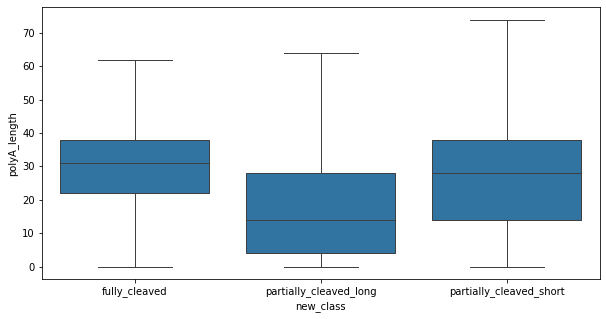

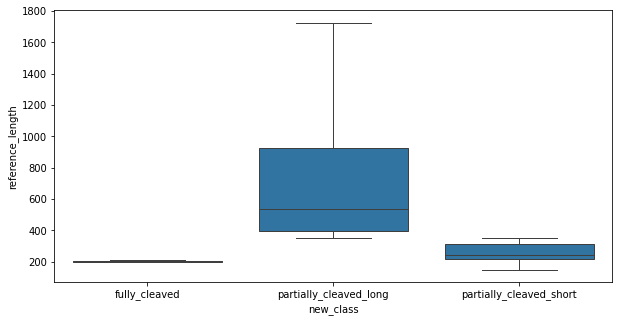

In [14]:
plt.figure(figsize=(10,5))
sn.boxplot(data=df_rev_new_class, x="new_class", y="polyA_length", showfliers=None)
plt.show()

plt.figure(figsize=(10,5))
sn.boxplot(data=df_rev_new_class, x="new_class", y="reference_length", showfliers=None)
plt.show()

In [16]:
df_rev_new_class.groupby("new_class")["polyA_length"].describe()

,count,mean,std,min,25%,50%,75%,max
new_class,,,,,,,,
fully_cleaved,53552.0,30.222980,14.090901,0.0,22.0,31.0,38.0,289.0
partially_cleaved_long,367166.0,18.194138,19.467687,0.0,4.0,14.0,28.0,668.0
partially_cleaved_short,369133.0,27.272495,18.798522,0.0,14.0,28.0,38.0,416.0


In [17]:
df_rev_new_class.groupby("new_class")["reference_length"].describe()

,count,mean,std,min,25%,50%,75%,max
new_class,,,,,,,,
fully_cleaved,53552.0,204.447472,24.727392,197.0,200.0,202.0,205.0,516.0
partially_cleaved_long,367166.0,734.196772,512.872026,353.0,397.0,540.0,929.0,7675.0
partially_cleaved_short,369133.0,258.230974,52.638567,150.0,219.0,246.0,312.0,352.0


In [26]:
# some checks
df_rev_new_class.sample(n=10)

,Chr,ChrStart,ChrEnd,read_id,MAPQ,strand,read_length,alignment_length,reference_length,polyA_length,sample,overlapping_gene_ids,overlapping_gene_names,n_overlapping_gene_ids,chrM_primary_class,new_class
2164314,chrM,10896,11526,beaa0e50-46fd-4a78-b611-3a79a0cdf819,60,-,643.0,630,630,16,GTD7,NaN,NaN,0,non_coding_region,partially_cleaved_long
455455,chrM,81,397,b7d5fbcb-ef82-40f2-9c9d-6a50ab0cf51a,60,-,341.0,302,316,41,GTA9,7S,7S,1,complete_gene,partially_cleaved_short
3393767,chrM,11033,11959,c5ab5a49-92cd-45c9-8460-eaeea3d5b4df,53,-,1051.0,1035,926,2,GTH2,NaN,NaN,0,non_coding_region,partially_cleaved_long
2411687,chrM,14535,14732,b1ab6185-3639-4ed1-bb9c-0ece569630fb,46,-,205.0,196,197,42,GTE2,"ENSG00000198695.2,ENSG00000210194.1","MT-ND6,MT-TE",2,precursor_gene,partially_cleaved_short
2167876,chrM,14501,14734,2d5751d9-1473-4de2-9b48-b69eec3efc35,60,-,238.0,231,233,37,GTD7,"ENSG00000198695.2,ENSG00000210194.1","MT-ND6,MT-TE",2,precursor_gene,partially_cleaved_short
1089861,chrM,4400,5750,a82943be-827d-4c12-8b0a-25fc4e4e0128,60,-,1364.0,1348,1350,2,GTB4,"ENSG00000210127.1,ENSG00000210135.1","MT-TA,MT-TN",2,precursor_gene,partially_cleaved_long
819657,chrM,3295,3514,d22617b9-caea-4bde-950d-a895eb2d5fd4,60,-,246.0,220,219,22,GTA9,NaN,NaN,0,non_coding_region,partially_cleaved_short
465140,chrM,153,395,e6d9c3ce-fc0d-4fd4-b60d-4d2d7aa26111,60,-,245.0,242,242,47,GTA9,7S,7S,1,complete_gene,partially_cleaved_short
431843,chrM,0,393,7f750463-2a56-4dad-877d-0ef28e2ec8e2,60,-,561.0,395,393,17,GTA9,7S,7S,1,complete_gene,partially_cleaved_long
1475568,chrM,153,395,bdd852b4-b71d-4e67-b482-2ec110859877,60,-,299.0,248,242,70,GTC8,7S,7S,1,complete_gene,partially_cleaved_short


In [25]:
df_rev_new_class.query("new_class == 'fully_cleaved'")["n_overlapping_gene_ids"].value_counts()

1    53552
Name: n_overlapping_gene_ids, dtype: int64

In [27]:
df_rev_new_class.query("new_class == 'fully_cleaved'")["overlapping_gene_names"].value_counts()

7S        53163
MT-ND6      389
Name: overlapping_gene_names, dtype: int64

In [32]:
df_rev_new_class.query("new_class == 'fully_cleaved'").describe()

,ChrStart,ChrEnd,MAPQ,read_length,alignment_length,reference_length,polyA_length,n_overlapping_gene_ids
count,53552.000000,53552.000000,53552.000000,53552.000000,53552.000000,53552.000000,53552.000000,53552.0
mean,295.685539,500.133011,59.994211,224.780195,205.626886,204.447472,30.222980,1.0
std,1186.948314,1211.427847,0.307094,28.285203,25.281649,24.727392,14.090901,0.0
min,189.000000,386.000000,29.000000,176.000000,165.000000,197.000000,0.000000,1.0
25%,191.000000,396.000000,60.000000,212.000000,200.000000,200.000000,22.000000,1.0
50%,194.000000,397.000000,60.000000,221.000000,203.000000,202.000000,31.000000,1.0
75%,197.000000,397.000000,60.000000,231.000000,206.000000,205.000000,38.000000,1.0
max,14191.000000,14667.000000,60.000000,794.000000,781.000000,516.000000,289.000000,1.0


In [28]:
df_rev_new_class.query("new_class == 'partially_cleaved_short'")["overlapping_gene_names"].value_counts()

7S                         238796
MT-ND6,MT-TE                16600
MT-TC,MT-TY                   395
MT-TP                         385
MT-TA,MT-TN                   173
MT-TS1                        171
MT-TA,MT-TN,MT-TC,MT-TY       106
MT-TN,MT-TC,MT-TY              52
MT-TY                          36
MT-TQ                          31
MT-TA,MT-TN,MT-TC               9
MT-TA                           8
MT-TE                           1
Name: overlapping_gene_names, dtype: int64

In [31]:
df_rev_new_class.query("new_class == 'partially_cleaved_short'").describe()

,ChrStart,ChrEnd,MAPQ,read_length,alignment_length,reference_length,polyA_length,n_overlapping_gene_ids
count,369133.000000,369133.000000,369133.000000,369133.000000,369133.000000,369133.000000,369133.000000,369133.000000
mean,4131.946152,4390.177126,58.260920,287.669943,259.414617,258.230974,27.272495,0.743285
std,6076.082736,6063.890556,5.908053,72.215025,54.300947,52.638567,18.798522,0.536907
min,0.000000,150.000000,20.000000,144.000000,131.000000,150.000000,0.000000,0.000000
25%,92.000000,397.000000,60.000000,236.000000,220.000000,219.000000,14.000000,0.000000
50%,171.000000,397.000000,60.000000,273.000000,247.000000,246.000000,28.000000,1.000000
75%,8930.000000,9206.000000,60.000000,336.000000,313.000000,312.000000,38.000000,1.000000
max,16419.000000,16569.000000,60.000000,1629.000000,764.000000,352.000000,416.000000,4.000000


In [30]:
df_rev_new_class.query("new_class == 'partially_cleaved_long'")["overlapping_gene_names"].value_counts()

7S                                      109480
MT-ND6                                   12267
MT-ND6,MT-TE                             11665
MT-TP                                     2173
MT-TS1                                    2083
MT-TC,MT-TY                               1717
MT-ND6,MT-TE,MT-TP                        1321
MT-TQ                                     1049
MT-TA,MT-TN,MT-TC,MT-TY                    972
MT-TA,MT-TN,MT-TC                          401
MT-TY                                      258
MT-TC,MT-TY,MT-TS1                         229
MT-TA,MT-TN                                225
MT-TA,MT-TN,MT-TC,MT-TY,MT-TS1             127
MT-TN,MT-TC,MT-TY                           83
MT-TY,MT-TS1                                54
MT-TE,MT-TP                                 50
MT-TQ,MT-TA                                 46
MT-TQ,MT-TA,MT-TN,MT-TC,MT-TY               35
MT-TQ,MT-TA,MT-TN,MT-TC                     20
MT-TQ,MT-TA,MT-TN                           19
MT-TN,MT-TC,M

In [33]:
df_rev_new_class.query("new_class == 'partially_cleaved_long'").describe()

,ChrStart,ChrEnd,MAPQ,read_length,alignment_length,reference_length,polyA_length,n_overlapping_gene_ids
count,367166.000000,367166.000000,367166.000000,367166.000000,367166.000000,367166.000000,367166.000000,367166.000000
mean,7414.390311,8148.587083,59.209401,839.856286,738.042351,734.196772,18.194138,0.451654
std,6083.352668,6221.863152,4.113665,504.030498,516.645130,512.872026,19.467687,0.630846
min,0.000000,386.000000,20.000000,305.000000,294.000000,353.000000,0.000000,0.000000
25%,0.000000,397.000000,60.000000,521.000000,398.000000,397.000000,4.000000,0.000000
50%,7590.000000,8531.000000,60.000000,681.000000,538.000000,540.000000,14.000000,0.000000
75%,13093.000000,14139.000000,60.000000,989.000000,936.000000,929.000000,28.000000,1.000000
max,16216.000000,16569.000000,60.000000,8492.000000,7667.000000,7675.000000,668.000000,6.000000
